# How a steering vector is found, and what steering does

A steering vector for a value (e.g. *fairness*) is found from VISPA's 100 sentence pairs for that value: each pair has a
"for" sentence (the value) and an "against" sentence (not the value) that differ only in that value. We take the model's
internal state for each sentence (the last word's state, at one layer), and the steering vector is the direction in which
the "for" and "against" states differ most consistently (`ethos.steering.activation.directions_from_states`, VISPA's recipe).

Steering adds `alpha x steering vector` to the model's internal state, which moves every sentence along that direction.

The saved sentence states are from **Qwen3-8B** (layers 10-25), captured in the VISPA equivalence check. Pick the value
and layer below; the next cell lists the values with saved states.

In [1]:
VALUE = "fairness"   # any value with saved states (listed below)
LAYER = 17           # 10-25
STATES_DIR = "../data/experiments/05_activation_steering/vispa_equivalence/vllm"
PAIRS_DIR = "../data/experiments/05_activation_steering/vispa_equivalence/pairs"
STATES = f"{STATES_DIR}/{VALUE}_states.npz"
FOR, AGAINST = VALUE.replace("_", " "), f"not {VALUE.replace('_', ' ')}"   # group names (same rule as the runs)

In [2]:
import glob
import os
import sys
import textwrap

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../src")
from ethos.steering.activation import directions_from_states

RED, BLUE = "#d1495b", "#2e6fac"                          # against, for
saved = sorted(os.path.basename(f).removesuffix("_states.npz") for f in glob.glob(f"{STATES_DIR}/*_states.npz"))
print("values with saved states:", ", ".join(saved))
assert VALUE in saved, f"no saved states for {VALUE!r}"

## 1. Load the sentence states and find the steering vector

`pos` / `neg`: one row per sentence, the model's internal state (4,096 numbers) for the "for" / "against" version.

In [3]:
z = np.load(STATES)
pos, neg = z[f"pos_{LAYER}"].astype(float), z[f"neg_{LAYER}"].astype(float)
d = directions_from_states({LAYER: pos}, {LAYER: neg})[LAYER].astype(float)
d /= np.linalg.norm(d)                                   # unit length: moving 1 along d = 1 unit of score
print(f"{len(pos)} pairs, {pos.shape[1]} numbers per state; typical state size {np.linalg.norm(pos, axis=1).mean():.1f}")

100 pairs, 4096 numbers per state; typical state size 88.8


## 2. Score each sentence along the steering vector

A sentence's score is how far its state points in the value's ("for") direction (multiply the two lists number by number and add
up), measured from the midpoint of all sentences.

It scores **how far each sentence’s hidden state lies along the steering direction `d`, relative to `center`, after steering**.

- A **positive** score means the state lies on the `+d` side of the center.
- A **negative** score means it lies on the `−d` side.
- The function returns one array of scores for `pos` and one for `neg`.

The important detail is that it **adds and measures along the same direction**. For any hidden state `h`,

\[
\text{score}_\alpha(h) = (h-\text{center})\cdot d + \alpha\|d\|^2.
\]

So if `d` is a unit vector, `alpha=2` adds exactly **2** to every score. The ranking and the gap between the groups stay the same. If you’re using this to evaluate moral-value steering, it measures the change you applied to the hidden state. To see whether the steering changes moderation behavior, compare the model’s **allow/remove outputs** across `alpha` values.

In [4]:
center = (pos.mean(0) + neg.mean(0)) / 2

def scores(alpha=0.0):
    """Each sentence's score after steering by alpha (alpha x vector added to its state)."""
    return (pos + alpha * d - center) @ d, (neg + alpha * d - center) @ d

p, n = scores()
print(f"'{AGAINST}' average {n.mean():+.1f}, '{FOR}' average {p.mean():+.1f}; "
      f"the '{FOR}' version is further right in {np.mean(p > n):.0%} of pairs")

unfair average -8.7, fair average +8.7; fair version further right in 100% of pairs


## 3. What steering does: every sentence moves by alpha

At one layer, adding `alpha x vector` shifts every score by exactly alpha; the gap between the groups stays the same.
In a real run the push is added at several layers, and the model's later layers react to it.

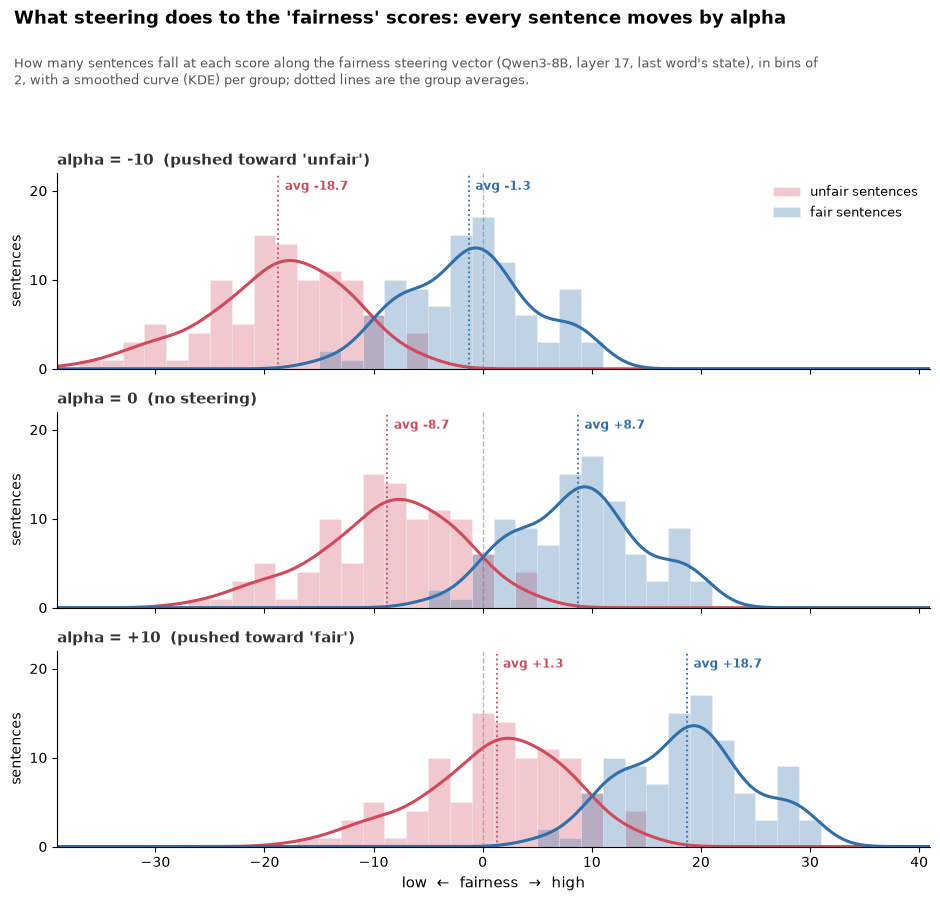

In [7]:
from scipy.stats import gaussian_kde

ALPHAS = [-10, 0, 10]
BIN = 2                                                   # histogram bin width (score units)

all_scores = np.concatenate([np.concatenate(scores(a)) for a in ALPHAS])
bins = np.arange(np.floor(all_scores.min()) - BIN, np.ceil(all_scores.max()) + 2 * BIN, BIN)
grid = np.linspace(bins[0] - 4, bins[-1] + 8, 500)        # where the smoothed curves are drawn
ymax = 1.3 * max(np.histogram(v, bins)[0].max() for a in ALPHAS for v in scores(a))   # room for the labels
pad = 0.01 * (bins[-1] - bins[0])                         # label offset from its line

fig, axes = plt.subplots(len(ALPHAS), 1, figsize=(9.5, 2.5 * len(ALPHAS) + 1.6), sharex=True, sharey=True)
for ax, a in zip(np.atleast_1d(axes), ALPHAS):
    p, n = scores(a)
    for vals, col, name in [(n, RED, f"'{AGAINST}' sentences"), (p, BLUE, f"'{FOR}' sentences")]:
        ax.hist(vals, bins=bins, color=col, alpha=0.3, edgecolor="white", lw=0.5, label=name)
        ax.plot(grid, gaussian_kde(vals)(grid) * len(vals) * BIN, color=col, lw=2.2)   # KDE scaled to counts
        ax.axvline(vals.mean(), color=col, lw=1.3, ls=":")
        ax.text(vals.mean() + pad, ymax * 0.96, f"avg {vals.mean():+.1f}", color=col, ha="left", va="top",
                fontsize=8.5, fontweight="bold")
    ax.axvline(0, color="#bbb", lw=1, ls="--", zorder=0)
    ax.set_ylim(0, ymax); ax.set_ylabel("sentences")
    ax.spines[["top", "right"]].set_visible(False)
    title = "alpha = 0  (no steering)" if a == 0 else f"alpha = {a:+g}  (pushed toward '{FOR if a > 0 else AGAINST}')"
    ax.set_title(title, loc="left", fontsize=10.5, fontweight="bold", color="#333")
axes[0].legend(frameon=False, loc="upper right", fontsize=9.5)
axes[-1].set_xlim(bins[0] - 4, bins[-1] + 8)
axes[-1].set_xlabel(f"low  \u2190  {FOR}  \u2192  high", fontsize=11)
fig.suptitle(f"What steering does to the '{FOR}' scores: every sentence moves by alpha",
             x=0.02, y=0.985, ha="left", fontsize=13, fontweight="bold")
sub = (f"How many sentences fall at each score along the {FOR} steering vector (Qwen3-8B, layer {LAYER}, "
       f"last word's state), in bins of {BIN}, with a smoothed curve (KDE) per group; dotted lines are the group averages.")
fig.text(0.02, 0.935, textwrap.fill(sub, 125), fontsize=9.5, color="#555", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()